# Employee attrition prediction: upgraded study

**Objective:** estimate an individual attrition-label probability, explain its major associated factors, and investigate whether domain-informed features improve prediction and interpretability together.

This notebook analyzes the actually executed repeated nested-CV experiment. Full training is a separate script because it includes 350 outer fits with tuning and 7,500 bootstrap refits. The data are fictional, have no defined forecast horizon, and have already been examined in an earlier single-split study. No human comprehension study was performed.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'attrition.py').exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Image
from attrition import DomainFeatures, linear_contributions, calibration_bins
from explanations import FEATURE_GUIDE, make_report, compare_reports
from train import load_data, outer_splits
RESULTS = ROOT / 'results'
pd.set_option('display.max_columns', 12)


## 1. Audit data and target
All 1,470 employees participate in repeated outer holdouts. Age, Gender and MaritalStatus are excluded from main models; only the explicit sensitivity model includes Age.

In [2]:
data, X, y = load_data()
display(pd.DataFrame({'count': data.Attrition.value_counts()}))
assert data.shape == (1470, 35) and int(y.sum()) == 237
print('Shape:', data.shape, 'Positive prevalence:', round(y.mean(), 4))
json.loads((RESULTS / 'data_audit.json').read_text())

Shape: (1470, 35) Positive prevalence: 0.1612


,count
Attrition,
No,1233
Yes,237


{'rows': 1470,
 'columns': 35,
 'positive': 237,
 'negative': 1233,
 'missing_cells': 0,
 'excluded_predictors': ['EmployeeNumber',
  'EmployeeCount',
  'Over18',
  'StandardHours',
  'Age',
  'Gender',
  'MaritalStatus'],
 'source_sha256': 'a5c31e38bd7fafc9bc333884eb181b06b41b8e5e488e8f7ccb27199fb3be7659',
 'unique_employees': 1470,
 'outer_test_observations_per_model': 7350,
 'outer_folds': 25}

## 2. Domain-informed representations
The original eight-feature design is preserved. A seven-feature candidate removes LogMonthlyIncome to avoid duplicate raw/log income attribution. Every learned role-income median is fit inside training folds.

In [3]:
display(pd.DataFrame(FEATURE_GUIDE, columns=['Block', 'Feature', 'Formula', 'Interpretation']))
for mode in ['raw', 'all', 'no_log']:
    transformer = DomainFeatures(mode).fit(X.iloc[:1000])
    print(mode, transformer.transform(X.iloc[[1001]]).shape[1], 'source attributes')

raw 27 source attributes
all 35 source attributes
no_log 34 source attributes


,Block,Feature,Formula,Interpretation
0,Workload,OvertimeBalancePressure,I(OverTime = Yes) × (5 − WorkLifeBalance),Overtime together with poorer reported work-li...
1,Workload,OvertimeCommute,I(OverTime = Yes) × DistanceFromHome,Commute distance in the context of overtime. T...
2,Career,PromotionDelayShare,YearsSinceLastPromotion / (YearsAtCompany + 1),Promotion delay relative to company tenure. Th...
3,Career,RoleTenureShare,YearsInCurrentRole / (YearsAtCompany + 1),Relative time in the current role; it need not...
4,Career,ManagerTenureShare,YearsWithCurrManager / (YearsAtCompany + 1),Manager continuity relative to tenure; it does...
5,Reward,IncomeToRoleMedian,MonthlyIncome / training role median income,Income relative to the same broad job role. Th...
6,Reward,LogMonthlyIncome,log(1 + MonthlyIncome),"A diminishing-scale representation of income, ..."
7,Sentiment,MeanDissatisfaction,"5 − mean(job, environment, relationship satisf...",Equal-weight summary of three ratings; not a v...


## 3. Matched repeated nested cross-validation
Outer: five repeats × five stratified folds. Inner: five folds, original eight-setting grid per family. Hyperparameters, preprocessing, sigmoid and threshold use outer-training data only. Calibration and threshold development reuse internal training scores; the untouched outer fold evaluates the complete procedure.

In [4]:
manifest = json.loads((RESULTS / 'split_manifest.json').read_text())
for (tr, te), fold in zip(outer_splits(X, y), manifest):
    assert list(tr) == fold['train_indices'] and list(te) == fold['test_indices']
    assert not set(tr) & set(te)
predictions = pd.read_csv(RESULTS / 'outer_predictions.csv.gz', float_precision='round_trip')
assert len(predictions) == 102900
assert predictions.groupby(['model', 'repeat']).row_index.nunique().eq(1470).all()
print('25 matched outer folds, 14 specifications, 7,350 held-out observations per specification.')

25 matched outer folds, 14 specifications, 7,350 held-out observations per specification.


## 4. Predictive performance
AP and ROC-AUC: higher is better. Brier: lower is better. Values are outer-fold means and sample SDs, not independent-repeat estimates. The selected model is refitted on all development rows.

In [5]:
summary = pd.read_csv(RESULTS / 'nested_cv_summary.csv')
core = summary[summary.feature_mode.isin(['raw', 'all', 'no_log'])]
core[['model', 'average_precision_mean', 'average_precision_std', 'roc_auc_mean', 'roc_auc_std', 'brier_mean', 'brier_std']].round(4)

,model,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,brier_mean,brier_std
0,forest_all,0.5397,0.0664,0.8011,0.0385,0.1049,0.0073
1,forest_no_log,0.5461,0.0644,0.8005,0.0356,0.1042,0.0070
2,forest_raw,0.5394,0.0682,0.7973,0.0379,0.1051,0.0078
3,logistic_all,0.6413,0.0463,0.8318,0.0302,0.0936,0.0065
4,logistic_no_log,0.6282,0.0501,0.8287,0.0311,0.0948,0.0065
6,logistic_raw,0.6172,0.0537,0.8254,0.0305,0.0962,0.0065
11,tree_all,0.3875,0.0575,0.7220,0.0404,0.1266,0.0027
12,tree_no_log,0.3855,0.0600,0.7253,0.0450,0.1264,0.0036
13,tree_raw,0.4007,0.0654,0.7257,0.0345,0.1258,0.0050


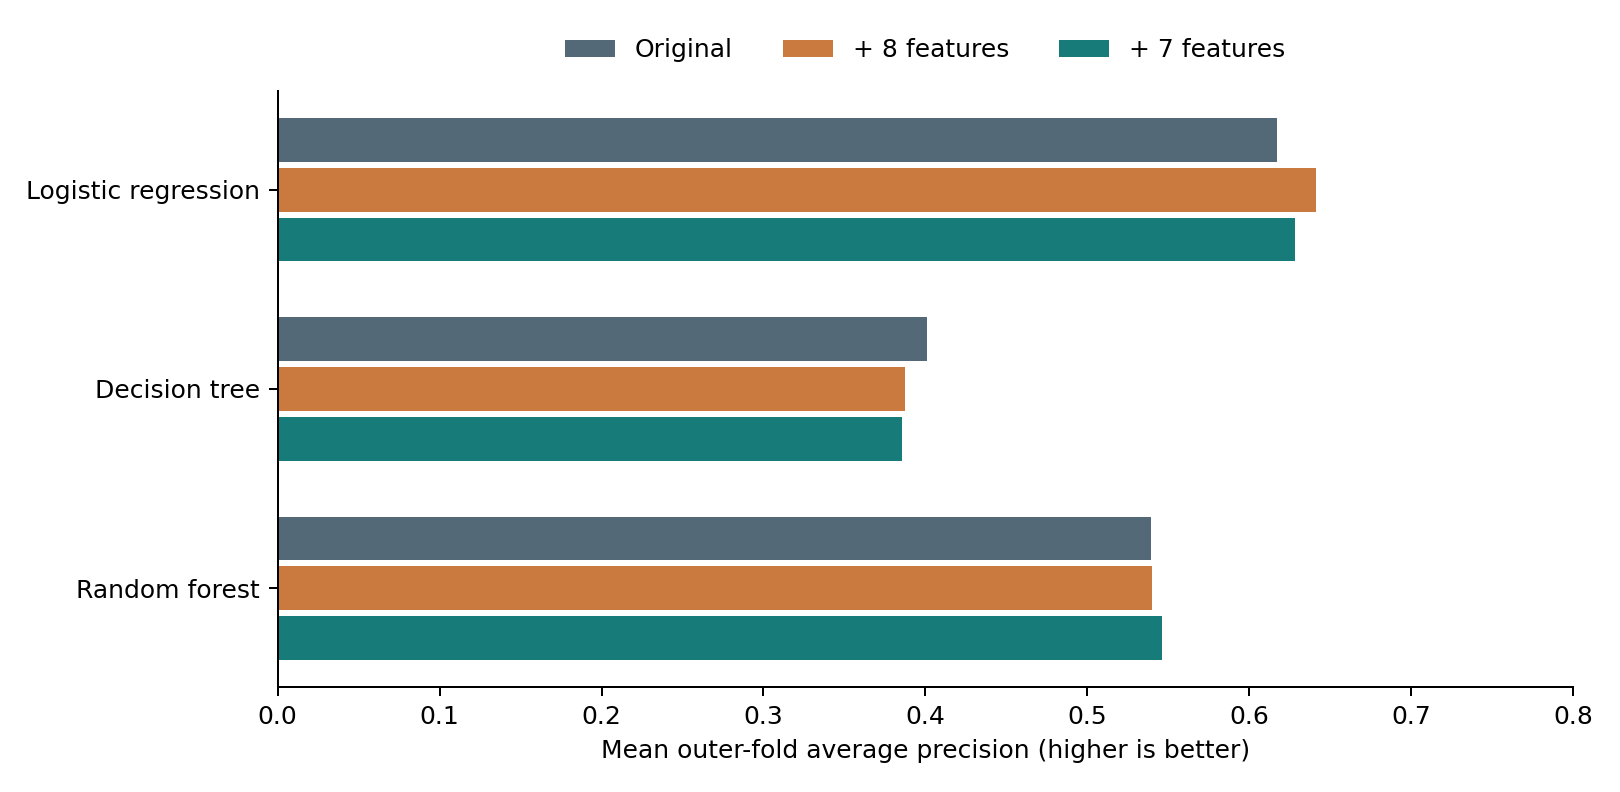

In [6]:
display(Image(filename=str(RESULTS / 'feature_comparison.png')))

## 5. Paired uncertainty
The corrected SE is sqrt((1/25 + 1/4) × variance of 25 paired differences). Intervals and tests use t(24); Holm adjustment covers three AP family tests separately within each specification. Overlapping folds are not independent. Selecting the winner across outer comparisons adds selection optimism; no new independent test is available.

In [7]:
paired = pd.read_csv(RESULTS / 'paired_comparisons.csv')
paired[(paired.metric == 'average_precision') & paired.comparison.isin(['all', 'no_log'])][['candidate', 'difference', 'ci_low', 'ci_high', 'wins', 'p_two_sided', 'p_holm_AP']].round(4)

,candidate,difference,ci_low,ci_high,wins,p_two_sided,p_holm_AP
0,logistic_all,0.0241,-0.0014,0.0496,23,0.0628,0.1884
3,tree_all,-0.0132,-0.0602,0.0339,8,0.5683,1.0000
6,forest_all,0.0002,-0.0266,0.0270,11,0.9874,1.0000
9,logistic_no_log,0.0111,-0.0131,0.0353,15,0.3551,1.0000
12,tree_no_log,-0.0152,-0.0636,0.0331,8,0.5222,1.0000
15,forest_no_log,0.0067,-0.0262,0.0395,14,0.6796,1.0000


## 6. Block ablations and age sensitivity
Ablations remove one engineered block from the seven-feature model; original predictors remain. Age sensitivity does not establish fairness. These diagnostics are exploratory and excluded from deployment selection.

In [8]:
display(summary[summary.feature_mode.str.startswith('without_') | summary.feature_mode.isin(['no_log', 'no_log_age'])][['model', 'average_precision_mean', 'roc_auc_mean', 'brier_mean']].round(4))
paired[paired.comparison.isin(['ablation', 'age']) & (paired.metric == 'average_precision')][['candidate', 'difference', 'ci_low', 'ci_high']].round(4)

,model,average_precision_mean,roc_auc_mean,brier_mean
1,forest_no_log,0.5461,0.8005,0.1042
4,logistic_no_log,0.6282,0.8287,0.0948
5,logistic_no_log_age,0.6311,0.8290,0.0941
7,logistic_without_career,0.6214,0.8243,0.0961
8,logistic_without_reward,0.6225,0.8292,0.0949
9,logistic_without_sentiment,0.6280,0.8286,0.0948
10,logistic_without_workload,0.6329,0.8306,0.0945
12,tree_no_log,0.3855,0.7253,0.1264


,candidate,difference,ci_low,ci_high
18,logistic_without_workload,0.0047,-0.0118,0.0212
21,logistic_without_career,-0.0069,-0.0286,0.0149
24,logistic_without_reward,-0.0057,-0.0204,0.0090
27,logistic_without_sentiment,-0.0003,-0.0024,0.0019
30,logistic_no_log_age,0.0029,-0.0115,0.0172


## 7. Calibration
Ten equal-width bins, ECE computed separately on each repeat’s held-out predictions. Pooled bin counts repeat the same employees. ECE depends on bins and sample size, and does not guarantee the full-data refit is calibrated.

Mean repeat ECE: 0.028721663271185333
SD across repeats: 0.0019417663064871284


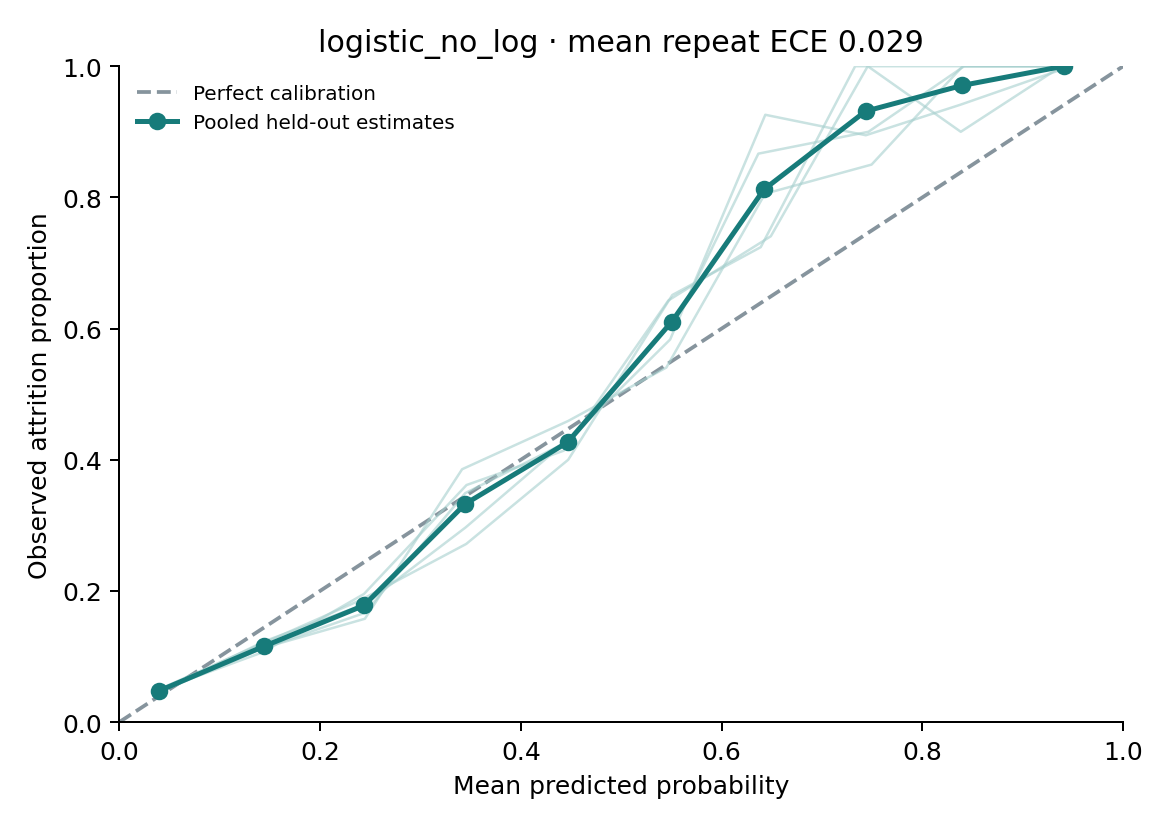

,bin,lower,upper,n,mean_probability,observed_rate
0,0,0.0,0.1,3913,0.0398,0.0478
1,1,0.1,0.2,1396,0.1437,0.1153
2,2,0.2,0.3,748,0.2437,0.1778
3,3,0.3,0.4,454,0.3446,0.3326
4,4,0.4,0.5,293,0.4466,0.4266
5,5,0.5,0.6,208,0.5504,0.6106
6,6,0.6,0.7,149,0.6421,0.8121
7,7,0.7,0.8,102,0.7434,0.9314
8,8,0.8,0.9,68,0.8394,0.9706
9,9,0.9,1.0,19,0.9407,1.0000


In [9]:
calibration = json.loads((RESULTS / 'calibration_summary.json').read_text())
print('Mean repeat ECE:', calibration['mean_repeat_ECE'])
print('SD across repeats:', calibration['sd_repeat_ECE'])
display(Image(filename=str(RESULTS / 'calibration_curve.png')))
pd.read_csv(RESULTS / 'reliability_pooled.csv').round(4)

## 8. Interpretation proxies on all held-out employees
K80 counts attributes covering 80% of absolute contribution mass. Top-three Jaccard measures agreement after 50 training bootstrap refits per outer fold. Logistic explanations use calibrated log-odds; forest TreeSHAP explains base probability before calibration. Intervals bootstrap five repeat means and describe conditional split variation, not population uncertainty.

In [10]:
interpretation = pd.read_csv(RESULTS / 'interpretability_summary.csv')
assert interpretation.unique_employees.eq(1470).all()
assert interpretation.refits_per_fold.eq(50).all()
interpretation[['model', 'metric', 'estimate', 'ci_low', 'ci_high']].round(4)

,model,metric,estimate,ci_low,ci_high
0,forest_all,mean_k80,16.2269,16.0377,16.4162
1,forest_all,top3_jaccard,0.4711,0.4642,0.4793
2,forest_all,spearman,0.3702,0.3204,0.4271
3,forest_no_log,mean_k80,15.3450,15.0586,15.6355
4,forest_no_log,top3_jaccard,0.4934,0.4885,0.4987
5,forest_no_log,spearman,0.3612,0.3282,0.3798
6,forest_raw,mean_k80,11.7347,11.2999,12.1695
7,forest_raw,top3_jaccard,0.5794,0.5740,0.5833
8,forest_raw,spearman,0.4412,0.3974,0.4807
9,logistic_all,mean_k80,13.1033,12.9561,13.2099


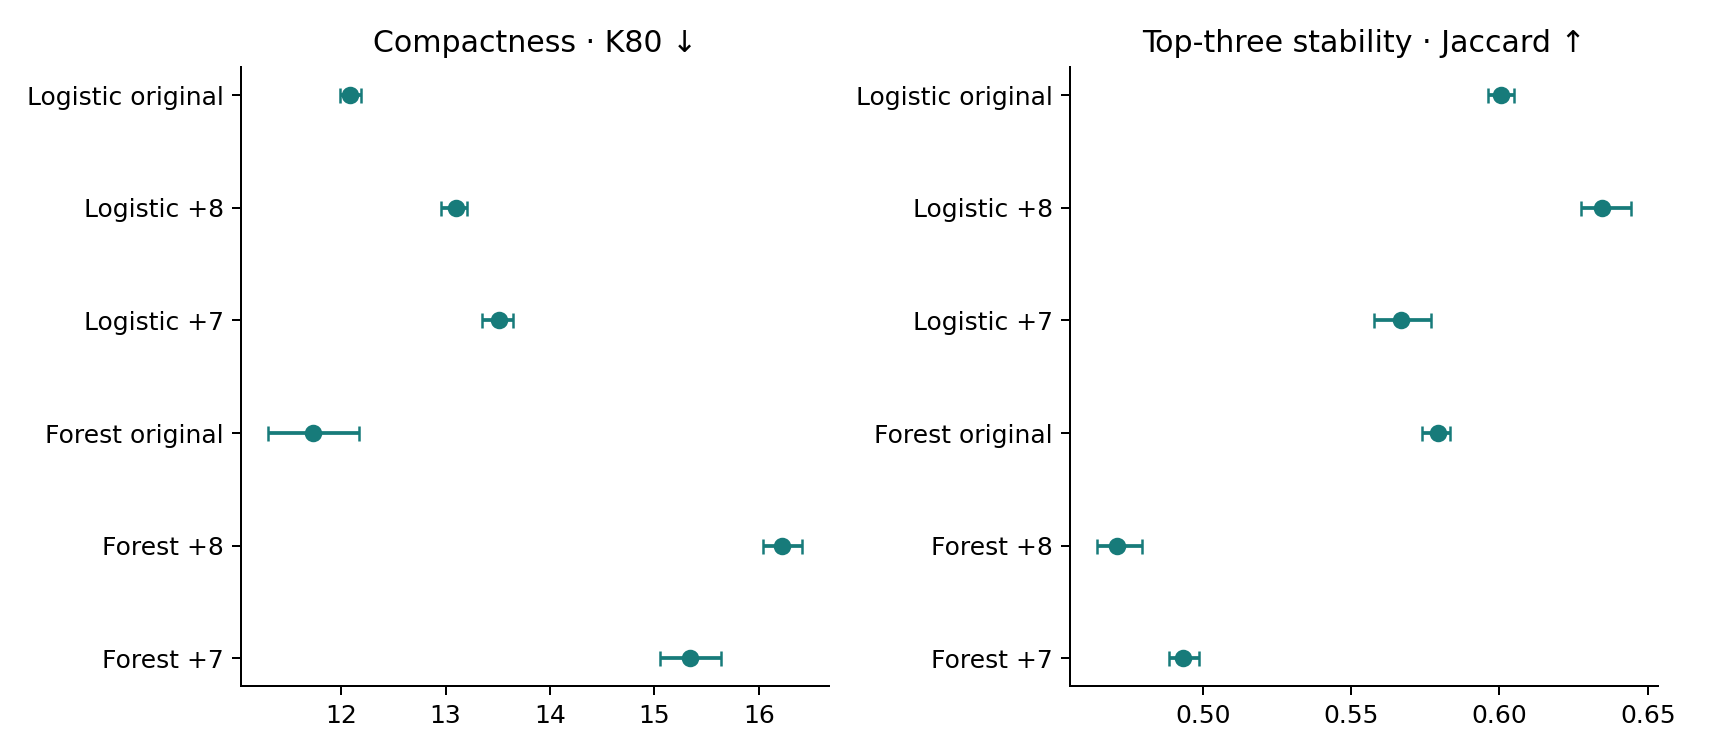

,reference,candidate,metric,difference,ci_low,ci_high
0,logistic_raw,logistic_all,mean_k80,1.0169,0.8867,1.1424
1,logistic_raw,logistic_all,top3_jaccard,0.0341,0.0255,0.0418
2,logistic_raw,logistic_all,spearman,0.0468,0.0289,0.0647
3,logistic_raw,logistic_no_log,mean_k80,1.4265,1.2514,1.6016
4,logistic_raw,logistic_no_log,top3_jaccard,-0.0338,-0.0401,-0.0274
5,logistic_raw,logistic_no_log,spearman,0.0109,-0.0115,0.0360
6,forest_raw,forest_all,mean_k80,4.4922,3.9294,5.0551
7,forest_raw,forest_all,top3_jaccard,-0.1083,-0.1167,-0.0956
8,forest_raw,forest_all,spearman,-0.0710,-0.1194,-0.0146
9,forest_raw,forest_no_log,mean_k80,3.6103,3.2053,3.9673


In [11]:
display(Image(filename=str(RESULTS / 'interpretability_comparison.png')))
pd.read_csv(RESULTS / 'interpretability_paired.csv').round(4)

## 9. Explanation ranking cross-check
Spearman compares mean absolute attribution ranks with held-out permutation AP-drop ranks. All one-hot levels of an attribute are permuted together. Derived columns are perturbed independently; inconsistent synthetic combinations can result. Ranking agreement is distinct from mathematical reconstruction and does not establish causal validity.

In [12]:
importance = pd.read_csv(RESULTS / 'global_attributions.csv')
importance[importance.model == 'logistic_no_log'].sort_values('mean_absolute_contribution', ascending=False).head(12).round(4)

,model,feature,mean_absolute_contribution,permutation_AP_drop
142,logistic_no_log,JobRole,0.7342,0.2211
149,logistic_no_log,OverTime,0.5854,0.1699
146,logistic_no_log,MonthlyIncome,0.5535,0.0973
158,logistic_no_log,TotalWorkingYears,0.4698,0.1261
156,logistic_no_log,RoleTenureShare,0.3539,0.0754
157,logistic_no_log,StockOptionLevel,0.3219,0.0533
148,logistic_no_log,NumCompaniesWorked,0.3156,0.0533
140,logistic_no_log,JobInvolvement,0.2718,0.0485
139,logistic_no_log,IncomeToRoleMedian,0.2427,0.0507
131,logistic_no_log,BusinessTravel,0.2416,0.0506


## 10. Same employee, original versus engineered
The prior illustrative employee 478 is reused. These example models did not train on that employee. It was previously chosen as a high-risk illustration, not a representative random example. The app’s final full-data model is separate.

In [13]:
example_bundle = joblib.load(ROOT / 'models/example_fold.joblib')
row = example_bundle['row']
comparison = compare_reports(example_bundle['models']['logistic_raw'], example_bundle['models']['logistic_no_log'], row)
for report in comparison.values():
    if isinstance(report, dict):
        assert report['group_additivity_error'] < 1e-9
        assert abs(report['feature_explanation']['reconstructed_probability'] - report['probability']) < 1e-9
pd.DataFrame([{'model': key, 'probability': comparison[key]['probability'], 'threshold': comparison[key]['threshold'], 'class': comparison[key]['predicted_label']} for key in ['original', 'engineered']])

,model,probability,threshold,class
0,original,0.951318,0.245,Attrition
1,engineered,0.940553,0.245,Attrition


Exported the computed comparison. Log-odds and probability points have different baselines and must not be mixed.


,display_name,value,contribution_calibrated_log_odds,definition
9,Overtime balance pressure,2.0,-0.331084,I(OverTime = Yes) × (5 − WorkLifeBalance)
11,Mean dissatisfaction,3.0,0.309636,"5 − mean(job, environment, relationship satisf..."
12,Income relative to role median,0.837926,0.292636,MonthlyIncome / training role median income
24,Overtime commute,1.0,-0.030088,I(OverTime = Yes) × DistanceFromHome
26,Role tenure share,0.5,-0.024357,YearsInCurrentRole / (YearsAtCompany + 1)
31,Manager tenure share,0.5,-0.003605,YearsWithCurrManager / (YearsAtCompany + 1)
33,Promotion delay share,0.25,-0.001535,YearsSinceLastPromotion / (YearsAtCompany + 1)


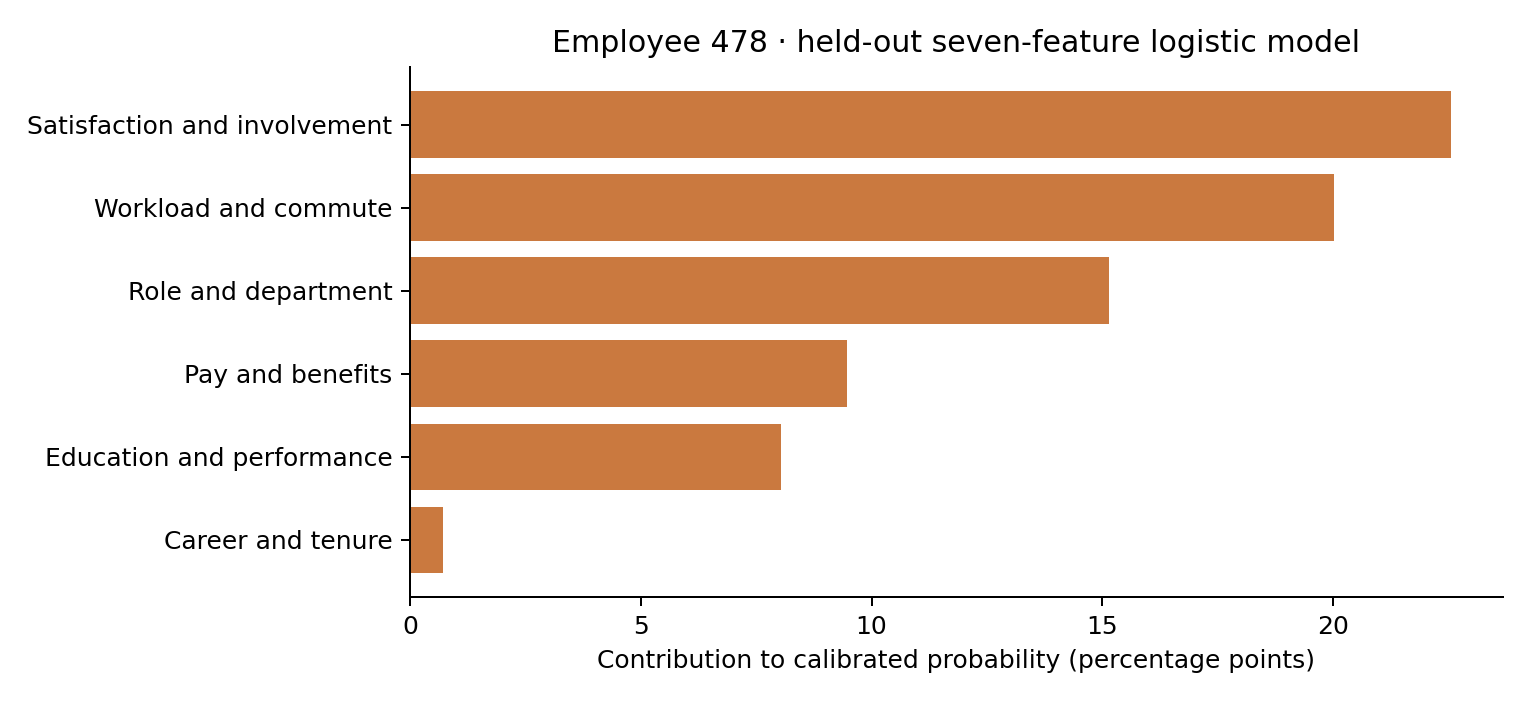

In [14]:
details = pd.DataFrame(comparison['engineered']['feature_explanation']['factors'])
display(details[details.is_engineered][['display_name', 'value', 'contribution_calibrated_log_odds', 'definition']])
display(Image(filename=str(RESULTS / 'example_factors.png')))
(ROOT / 'outputs/notebook_employee_explanation.json').write_text(json.dumps(comparison, indent=2, allow_nan=False))
print('Exported the computed comparison. Log-odds and probability points have different baselines and must not be mixed.')

## 11. Final model and measured answer
Candidate selection uses mean outer AP among original/seven-feature models, then lower Brier and model key. A full-data refit uses training CV calibration and threshold selection. Demonstration predictions on those training records are not evaluation results.

In [15]:
bundle = joblib.load(ROOT / 'models/bundle.joblib')
model = bundle['models'][bundle['selected']]
print('Selected model:', bundle['selected'], 'Final threshold:', model.threshold)
conclusion = json.loads((RESULTS / 'conclusion.json').read_text())
for field in ['answer', 'comparison_statement', 'eight_feature_interpretability']:
    print(conclusion[field])

Selected model: logistic_no_log Final threshold: 0.29
The study does not demonstrate simultaneous improvement in prediction and interpretability for the seven-feature logistic model; the measured trade-offs must be reported separately. The seven-feature logistic model changes mean average precision from 0.6172 to 0.6282 (paired difference +0.0111; corrected 95% interval [-0.0131, +0.0353]). Top-three stability changes by -0.0338, while K80 changes by +1.43 attributes (lower K80 is better). No human clarity study has been performed.
The original eight-feature logistic arm has mean AP 0.6413, a change of +0.0241 versus original predictors (corrected 95% interval [-0.0014, +0.0496]; 23/25 fold wins). Forest AP changes are +0.0002 with eight features and +0.0067 with seven; their corrected intervals include zero. Both engineered decision-tree arms have lower mean AP than the original arm.
For the eight-feature logistic arm, stability changes by +0.0341 and K80 by +1.02. Interpretability di

## 12. Reproduce and extend
Run `python reproduce.py --destination ../Attrition_Reproduced --jobs 6` from the project root to repeat the complete experiment in a new folder. Run `python verify.py` to validate the supplied artifacts. The optional human-study rubric uses 5–10 classmates and anonymous, counterbalanced 1–5 ratings. **It has not been performed.**

Limitations: fictional cross-sectional data, unknown timing and horizon, previously examined data, winner-selection optimism, dependent folds, five-repeat descriptive interpretation intervals, correlated features and no external, human-understanding or fairness validation. Read `docs/METHODOLOGY.md` for definitions and primary references.